<a href="https://colab.research.google.com/github/charlottedelphinar/maths-stats-ml-project-22102026-cdr/blob/main/ml_project_fraud_detection_decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fraud Detection with a Decision Tree Implemented from Scratch
### Mathematics & Statistics for Machine Learning project

---

**Authors:** Grégoire Mismaque, Charlotte Delphina Rupp, Maïane Benech

**Oral defence:** 20 November 2026

**Research question:** Can a decision tree that we implemented from scratch in NumPy detect fraudulent transactions before they are executed, and how closely do its results match those of scikit-learn's `DecisionTreeClassifier`?

**What we did:** We wrote the core of the tree ourselves: the impurity computation, the search for the best split, the recursive construction of the tree and the prediction. We used scikit-learn only as a benchmark and to compute evaluation metrics.

**Structure:**

| Section | Step |
|:--|:--|
| 1 | Understanding the data |
| 2 | Chronological split into training, validation and test sets |
| 3 | Exploratory data analysis (EDA) on the training set |
| 4 | Feature engineering |
| 5 | Mathematics of the decision tree (Gini impurity, split search, class weights) |
| 6 | Verification of the implementation |
| 7 | Training of our tree and of the scikit-learn benchmark |
| 8 | Threshold selection on the validation set |
| 9 | Final evaluation on the test set |
| 10 | Interpretation and error analysis |
| 10.1 | Why the model works: learned rules |
| 10.2 | Sensitivity of the decision threshold |
| 10.3 | Ablation study and stability over time |
| 10.4 | Summary dashboard |
| 11 | Discussion, limitations and conclusion |

In [1]:
%pip install -q kagglehub scikit-learn seaborn

In [2]:
import glob
import os
import time
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import kagglehub
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
    precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
N_ROWS = 500_000
MAX_DEPTH = 6
MIN_SAMPLES_LEAF = 20
USE_TIME = False
OUTPUT_DIR = "project_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Python :", platform.python_version())
print("NumPy :", np.__version__, "pandas :", pd.__version__, "sklearn :", sklearn.__version__)

Python : 3.13.18
NumPy : 2.4.6 pandas : 2.2.3 sklearn : 1.6.1


## 1. Understanding the data

We worked with the PaySim dataset from Kaggle: https://www.kaggle.com/datasets/amanalisiddiqui/fraud-detection-dataset

PaySim is a simulator that generates mobile-money transactions. Each transaction has an `isFraud` label (0 = legitimate, 1 = fraud). Fraud is very rare: a model that always predicts "legitimate" would already be correct for about 99.87 % of the transactions in the full dataset. For this reason we could not judge our model with accuracy alone.

**Which information we used:** Our goal was to decide *before* a transaction is executed whether it is fraudulent. We therefore kept only the transaction type, the amount and the balances recorded before the transaction. We left out three things: the balances after the transaction, because they reveal the outcome; the account identifiers, which are not predictive features; and `isFlaggedFraud`, because it is the output of another detection rule. The variable `step` is one simulated hour. We used it to keep the chronological order of the data, not as a predictor.

**Why before the transaction:** In earlier exploratory runs, we found that residuals computed from post-transaction balances make fraud detection almost trivial on PaySim. We therefore chose the harder and more meaningful question: what can we detect with the information available before the transaction? Whether these balances are really available at decision time would have to be checked in a real system.

In [3]:
folder = kagglehub.dataset_download("amanalisiddiqui/fraud-detection-dataset")
csv_file = sorted(glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True))[0]
columns = ["step", "type", "amount", "oldbalanceOrg", "oldbalanceDest", "isFraud"]
data = pd.read_csv(csv_file, usecols=columns)
data["source_row"] = np.arange(len(data))
if N_ROWS is not None and len(data) > N_ROWS:
    data = data.sample(n=N_ROWS, random_state=SEED)
data = data.sort_values(["step", "source_row"]).reset_index(drop=True)
print("Number of transactions:", len(data))
print("Missing values:")
print(data.isna().sum())
assert data[columns].notna().all().all(), "Define how to handle missing values before continuing."
assert set(data.isFraud.unique()) == {0, 1}
display(data.head())

100%|██████████| 178M/178M [00:02<00:00, 72.6MB/s]

Extracting files...


Number of transactions: 500000
Missing values:
step              0
type              0
amount            0
oldbalanceOrg     0
oldbalanceDest    0
isFraud           0
source_row        0
dtype: int64


,step,type,amount,oldbalanceOrg,oldbalanceDest,isFraud,source_row
0,1,PAYMENT,9839.64,170136.00,0.0,0,0
1,1,PAYMENT,11633.76,10127.00,0.0,0,13
2,1,CASH_OUT,229133.94,15325.00,5083.0,0,15
3,1,PAYMENT,1563.82,450.00,0.0,0,16
4,1,CASH_OUT,110414.71,26845.41,288800.0,0,42


## 2. Chronological split into training, validation and test sets

We split the data chronologically. We used about the first 60 % of the rows to train the tree, the next 20 % to choose the decision threshold (validation) and the last 20 % for the final evaluation (test). We moved each boundary to the start of a whole simulated hour, so no hour appears in two sets. The notebook prints the actual proportions and fraud rates.

**How we avoided data leakage:**
- We fixed the hyperparameters in advance, in the configuration cell.
- We chose the threshold on the validation set, never on the test set.
- We ran the exploratory data analysis on the training set only.
- We used no oversampling and no normalisation. A tree only compares values with thresholds, so a monotonic rescaling of a feature does not change its splits, and we used class weights instead of resampling.

In [4]:
cut_train = data.step.iloc[int(0.60 * len(data))]
cut_val = data.step.iloc[int(0.80 * len(data))]
train = data[data.step < cut_train].copy()
val = data[(data.step >= cut_train) & (data.step < cut_val)].copy()
test = data[data.step >= cut_val].copy()
assert train.step.max() < val.step.min()
assert val.step.max() < test.step.min()
for part in [train, val, test]:
    assert part.isFraud.nunique() == 2, "Each set must contain both classes."

split_table = pd.DataFrame([
    {"set": name, "rows": len(part), "frauds": int(part.isFraud.sum()),
     "fraud_rate": part.isFraud.mean(), "first_hour": part.step.min(),
     "last_hour": part.step.max()}
    for name, part in [("train", train), ("validation", val), ("test", test)]
])
display(split_table)

,set,rows,frauds,fraud_rate,first_hour,last_hour
0,train,297875,238,0.000799,1,280
1,validation,100285,62,0.000618,281,354
2,test,101840,347,0.003407,355,742


## 3. Exploratory data analysis (EDA) on the training set

We explored the training set only, so that nothing from the validation or test period could influence our modelling choices. We looked at the fraud rate by transaction type, the distribution of the amounts on a log scale and the fraud rate by hour phase. Before interpreting a high rate, we always checked how many transactions it was based on.

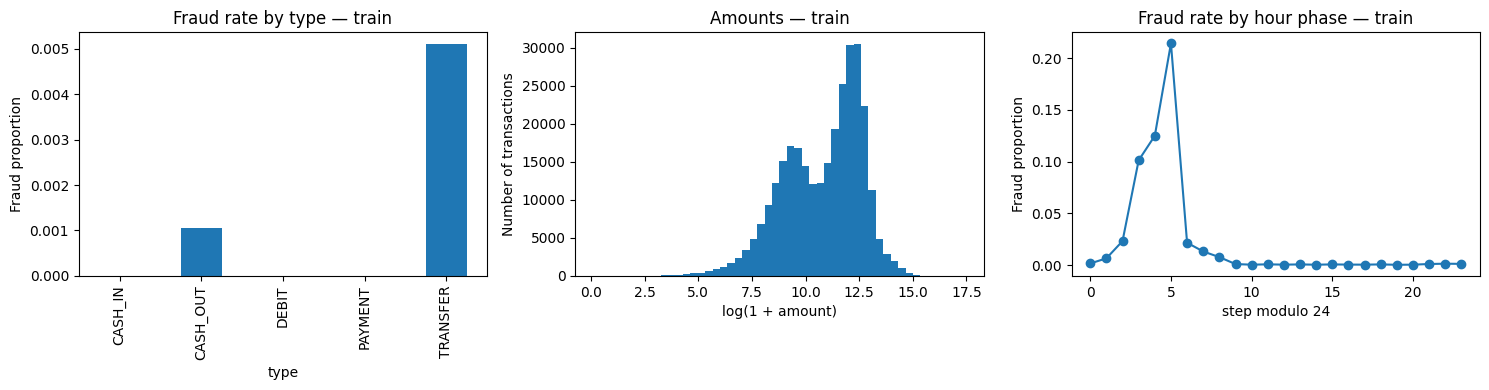

,sum,count,mean
type,,,
CASH_IN,0,65397,0.000000
CASH_OUT,112,105809,0.001059
DEBIT,0,1801,0.000000
PAYMENT,0,100190,0.000000
TRANSFER,126,24678,0.005106


,sum,count,mean
step,,,
0,5,3194,0.001565
1,9,1385,0.006498
2,9,388,0.023196
3,8,79,0.101266
4,7,56,0.125000
5,15,70,0.214286
6,3,139,0.021583
7,7,533,0.013133
8,13,1691,0.007688


In [5]:
by_type = train.groupby("type").isFraud.agg(["sum", "count", "mean"])
by_hour = train.groupby(train.step % 24).isFraud.agg(["sum", "count", "mean"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
by_type["mean"].plot.bar(ax=axes[0], title="Fraud rate by type — train")
axes[0].set_ylabel("Fraud proportion")
axes[1].hist(np.log1p(train.amount), bins=50)
axes[1].set_title("Amounts — train"); axes[1].set_xlabel("log(1 + amount)")
axes[1].set_ylabel("Number of transactions")
axes[2].plot(by_hour.index, by_hour["mean"], marker="o")
axes[2].set_title("Fraud rate by hour phase — train")
axes[2].set_xlabel("step modulo 24"); axes[2].set_ylabel("Fraud proportion")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/exploration.png", dpi=150)
plt.show()
display(by_type)
# Check volumes before interpreting a high rate.
display(by_hour)

## 4. Feature engineering

**What we built:** We kept the number of features small:
- the amount, the sender's old balance and the recipient's old balance;
- the ratio *amount / sender's old balance*, a relative measure of the size of the transaction;
- an indicator equal to 1 when the sender's initial balance is zero;
- the transaction type, encoded as 0/1 columns from an explicit list of categories.

**Design choices:** To avoid a division by zero, we bounded the denominator of the ratio below by 1 currency unit, and we capped the ratio at one million. This is a modelling choice, and we discuss it in the limitations. When the sender's balance is zero, the ratio simply equals the amount. No value of the target enters these calculations.

**Hour phase:** We also prepared the hour phase (`step` modulo 24, switched on with `USE_TIME=True`). We left it off by default because its contribution was irregular in our earlier checks. Using it would require defining the experiment first and comparing it on the validation set before consulting a new test set. Note that this phase is not a real clock hour.

In [6]:
TYPES = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]

def make_features(frame):
    features = frame[["amount", "oldbalanceOrg", "oldbalanceDest"]].copy()
    features["amount_to_balance"] = (
        frame.amount / frame.oldbalanceOrg.clip(lower=1)
    ).clip(upper=1_000_000)
    features["zero_balance"] = (frame.oldbalanceOrg == 0).astype(int)
    for transaction_type in TYPES:
        features["type_" + transaction_type] = (frame.type == transaction_type).astype(int)
    if USE_TIME:
        features["hour_phase"] = frame.step % 24
    return features

assert set(data.type.unique()).issubset(TYPES)
feature_names = make_features(train).columns.tolist()
# float32 for NumPy too: sklearn converts inputs to float32.
X_train = make_features(train).to_numpy(dtype=np.float32)
X_val = make_features(val).to_numpy(dtype=np.float32)
X_test = make_features(test).to_numpy(dtype=np.float32)
y_train = train.isFraud.to_numpy(dtype=int)
y_val = val.isFraud.to_numpy(dtype=int)
y_test = test.isFraud.to_numpy(dtype=int)
assert all(np.isfinite(x).all() for x in [X_train, X_val, X_test])
print("Features:", feature_names)
print("Train shape:", X_train.shape)

Features: ['amount', 'oldbalanceOrg', 'oldbalanceDest', 'amount_to_balance', 'zero_balance', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Train shape: (297875, 10)


## 5. Mathematics of the decision tree

**How the tree decides:** At each node, our tree asks one question: **is a feature less than or equal to a threshold?** Observations that answer yes go to the left child, the others to the right.

**Impurity:** We measure how mixed a node is with the Gini impurity. For a weighted fraud proportion $p$, it is
$$G(p) = 1 - p^2 - (1-p)^2 = 2p(1-p).$$
It is zero for a pure node and maximal ($0.5$) when $p = 0.5$.

**Cost of a split:** We score every candidate split by the weighted impurity of its two children:
$$\text{cost} = \frac{W_l}{W}\,G(p_l) + \frac{W_r}{W}\,G(p_r),$$
where $W_l$ and $W_r$ are the sums of the weights on the left and on the right, and $W = W_l + W_r$. Our algorithm keeps the split with the smallest cost and then repeats the procedure in each child. This search is **greedy**: it optimises each split on its own, not the whole tree.

**Class weights:** Fraud is much rarer than legitimate activity, so we gave the fraud cases more weight: $w_i = n / (2\,n_{y_i})$, where $n$ is the size of the training set and $n_{y_i}$ is the number of training observations in the class of observation $i$. Each class then carries the same total weight. We computed the weights on the training set only, and we gave the same weights to both trees.

**Stopping rules:** We stop growing a branch when the maximum depth is reached, when a node is pure, when it has too few observations to form two leaves, or when no split improves the impurity. A leaf returns its weighted fraud proportion. This score is not a calibrated probability.

**Split search:** For each feature, we sort the values, compute cumulative sums of the weights and test every midpoint between two distinct values that respects the minimum leaf size. The cost of one node is approximately $O(d\,n\log n)$ for $d$ features and $n$ observations. Limiting the depth reduces both overfitting and computing time.

In [7]:
def gini(probability):
    return 2 * probability * (1 - probability)


def best_split(X, y, weights, min_leaf):
    """Find the best feature and threshold for a node."""
    n_rows, n_features = X.shape
    total_weight = weights.sum()
    total_fraud_weight = np.sum(weights * y)
    best_cost = gini(total_fraud_weight / total_weight)
    best_feature = None
    best_threshold = None

    for feature in range(n_features):
        order = np.argsort(X[:, feature], kind="stable")
        values = X[order, feature]
        sorted_weights = weights[order]
        sorted_labels = y[order]

        left_weight = np.cumsum(sorted_weights)[:-1]
        left_fraud = np.cumsum(sorted_weights * sorted_labels)[:-1]
        right_weight = total_weight - left_weight
        right_fraud = total_fraud_weight - left_fraud
        left_count = np.arange(1, n_rows)

        valid = ((values[:-1] < values[1:]) &
                 (left_count >= min_leaf) & (n_rows - left_count >= min_leaf) &
                 (left_weight > 0) & (right_weight > 0))
        positions = np.flatnonzero(valid)
        if len(positions) == 0:
            continue

        p_left = np.clip(left_fraud[positions] / left_weight[positions], 0, 1)
        p_right = np.clip(right_fraud[positions] / right_weight[positions], 0, 1)
        costs = (left_weight[positions] * gini(p_left) +
                 right_weight[positions] * gini(p_right)) / total_weight
        position_in_costs = np.argmin(costs)
        cost = costs[position_in_costs]
        if cost < best_cost - 1e-12:
            position = positions[position_in_costs]
            best_cost = cost
            best_feature = feature
            # Convert to float64 before computing the midpoint.
            best_threshold = (float(values[position]) + float(values[position + 1])) / 2

    return best_feature, best_threshold

In [8]:
class DecisionTreeScratch:
    """Binary classification tree, implemented with NumPy only."""

    def __init__(self, max_depth=6, min_samples_leaf=20):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y, weights):
        self.root = self._grow(X, y, weights, depth=0)
        return self

    def _grow(self, X, y, weights, depth):
        probability = float(np.sum(weights * y) / weights.sum())
        node = {"score": probability, "n": len(y)}
        stop = (depth >= self.max_depth or
                len(y) < 2 * self.min_samples_leaf or
                np.all(y == y[0]))
        if stop:
            return node

        feature, threshold = best_split(X, y, weights, self.min_samples_leaf)
        if feature is None:
            return node

        left = X[:, feature] <= threshold
        node["feature"] = feature
        node["threshold"] = threshold
        node["left"] = self._grow(X[left], y[left], weights[left], depth + 1)
        node["right"] = self._grow(X[~left], y[~left], weights[~left], depth + 1)
        return node

    def predict_proba(self, X):
        scores = np.empty(len(X), dtype=float)
        self._predict_node(self.root, X, np.arange(len(X)), scores)
        return scores

    def _predict_node(self, node, X, rows, scores):
        if len(rows) == 0:
            return
        if "feature" not in node:
            scores[rows] = node["score"]
            return
        left = X[rows, node["feature"]] <= node["threshold"]
        self._predict_node(node["left"], X, rows[left], scores)
        self._predict_node(node["right"], X, rows[~left], scores)

## 6. Verification of the implementation

Before using the real data, we tested our tree on a small dataset where we knew the best split. We also tested two special cases: a pure node, which must not be split, and a constant feature, which offers no split. These checks do not prove that the code is correct, but they catch simple construction errors.

We gave the scikit-learn benchmark the same Gini criterion, weights, features, rows, depth and minimum leaf size. The two trees can still differ, because scikit-learn breaks some ties differently and applies its own numerical tolerances. We therefore did not require the two trees to be exactly identical.

In [9]:
toy_X = np.array([[0], [1], [2], [3]], dtype=np.float32)
toy_y = np.array([0, 0, 1, 1])
toy_w = np.ones(4)
feature, threshold = best_split(toy_X, toy_y, toy_w, min_leaf=1)
assert feature == 0 and threshold == 1.5
small_tree = DecisionTreeScratch(max_depth=1, min_samples_leaf=1).fit(toy_X, toy_y, toy_w)
np.testing.assert_allclose(small_tree.predict_proba(toy_X), toy_y)
pure_tree = DecisionTreeScratch().fit(toy_X, np.zeros(4, dtype=int), toy_w)
assert "feature" not in pure_tree.root
constant_tree = DecisionTreeScratch(min_samples_leaf=1).fit(np.ones((4, 1)), toy_y, toy_w)
np.testing.assert_allclose(constant_tree.predict_proba(np.ones((2, 1))), [.5, .5])
library_toy = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(toy_X, toy_y)
np.testing.assert_allclose(library_toy.predict_proba(toy_X)[:, 1], small_tree.predict_proba(toy_X))
print("Checks passed")

Checks passed


## 7. Training of our tree and of the scikit-learn benchmark

We trained our tree and the scikit-learn tree on the same training rows, with the same features, class weights, depth and minimum leaf size. The class weights change the impurity so that fraud cases count for more. They do not change the fraud proportion in the validation and test sets. We measured the training time for the fitting step only.

In [10]:
counts = np.bincount(y_train, minlength=2)
weights = len(y_train) / (2 * counts[y_train])

start = time.perf_counter()
scratch = DecisionTreeScratch(MAX_DEPTH, MIN_SAMPLES_LEAF)
scratch.fit(X_train, y_train, weights)
scratch_seconds = time.perf_counter() - start

start = time.perf_counter()
benchmark = DecisionTreeClassifier(criterion="gini", max_depth=MAX_DEPTH,
    min_samples_leaf=MIN_SAMPLES_LEAF, random_state=SEED)
benchmark.fit(X_train, y_train, sample_weight=weights)
benchmark_seconds = time.perf_counter() - start

models = {"NumPy tree": scratch, "sklearn tree": benchmark}
fit_times = {"NumPy tree": scratch_seconds, "sklearn tree": benchmark_seconds}
print("Training time:", fit_times)

Training time: {'NumPy tree': 1.7328950159999863, 'sklearn tree': 2.139671501999999}


## 8. Threshold selection on the validation set

The weighted fraud proportion in a leaf is a **score**, so the default threshold of 0.5 is not necessarily the best choice. For each model, we chose the threshold that maximises the F1-score on the validation set. We see this as a pedagogical compromise between precision and recall; an operational system would need an explicit cost or a fixed budget of false alarms.

**Metrics we report:**
- *Precision*: the share of alerts that are true frauds.
- *Recall*: the share of frauds that are detected.
- *Average Precision (AP)*: the quality of the ranking, without fixing a threshold.
- The numbers of false positives (FP) and false negatives (FN), and the number of false alarms per 10,000 transactions.

We did not optimise any threshold on the test set.

In [11]:
def model_scores(model, X):
    scores = model.predict_proba(X)
    return scores if scores.ndim == 1 else scores[:, 1]


def choose_f1_threshold(y, scores):
    precision, recall, thresholds = precision_recall_curve(y, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[np.argmax(f1)])


def evaluate(y, scores, threshold):
    predicted = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {"AP": average_precision_score(y, scores),
            "precision": precision_score(y, predicted, zero_division=0),
            "recall": recall_score(y, predicted, zero_division=0),
            "F1": f1_score(y, predicted, zero_division=0),
            "FP": int(fp), "FN": int(fn), "TP": int(tp), "TN": int(tn),
            "FP_per_10000": 10000 * fp / len(y)}

thresholds = {}
validation_rows = []
for name, model in models.items():
    scores = model_scores(model, X_val)
    thresholds[name] = choose_f1_threshold(y_val, scores)
    validation_rows.append({"model": name, "threshold": thresholds[name],
                            **evaluate(y_val, scores, thresholds[name])})
validation_results = pd.DataFrame(validation_rows)
display(validation_results)

,model,threshold,AP,precision,recall,F1,FP,FN,TP,TN,FP_per_10000
0,NumPy tree,1.0,1.0,1.0,1.0,1.0,0,0,62,100223,0.0
1,sklearn tree,1.0,1.0,1.0,1.0,1.0,0,0,62,100223,0.0


## 9. Final evaluation on the test set

**Rule we followed:** We evaluated all planned models once on the test set, in order to compare the methods. We did not use these results to choose new parameters, for example by running the test evaluation again. We kept the notebook outputs for the submission.

**What we report:** precision, recall, F1-score, Average Precision (AP), the confusion-matrix counts (TP, FP, FN, TN), the number of false alarms per 10,000 transactions and the training time. We also plot the precision–recall curves, with the fraud prevalence of the test set as a reference, and the confusion matrix of our NumPy tree.

,model,training_seconds,threshold,AP,precision,recall,F1,FP,FN,TP,TN,FP_per_10000
0,NumPy tree,1.732895,1.0,0.996672,1.0,0.976945,0.988338,0,8,339,101493,0.0
1,sklearn tree,2.139672,1.0,0.996672,1.0,0.976945,0.988338,0,8,339,101493,0.0


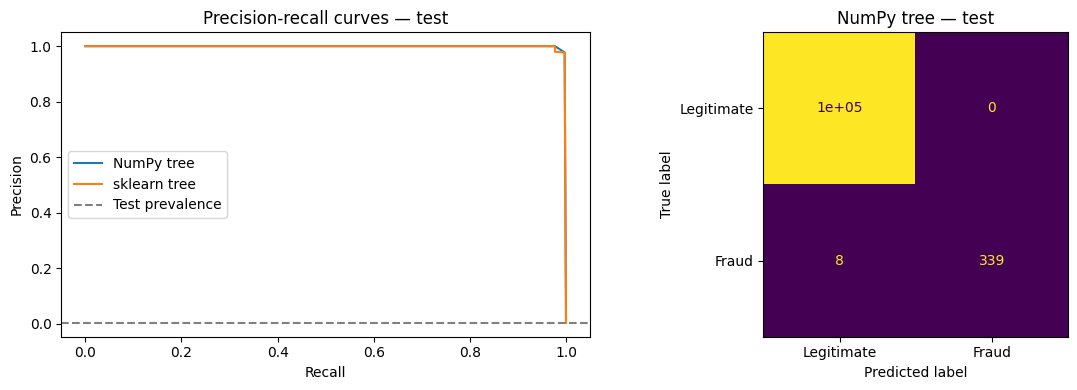

In [12]:
test_scores = {}
rows = []
for name, model in models.items():
    test_scores[name] = model_scores(model, X_test)
    rows.append({"model": name, "training_seconds": fit_times[name],
                 "threshold": thresholds[name],
                 **evaluate(y_test, test_scores[name], thresholds[name])})
results = pd.DataFrame(rows)
display(results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[0].plot(recall, precision, label=name)
axes[0].axhline(y_test.mean(), linestyle="--", color="gray", label="Test prevalence")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-recall curves — test"); axes[0].legend()
predicted = test_scores["NumPy tree"] >= thresholds["NumPy tree"]
ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0, 1],
    display_labels=["Legitimate", "Fraud"], colorbar=False, ax=axes[1])
axes[1].set_title("NumPy tree — test")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/evaluation.png", dpi=150)
plt.show()

## 10. Interpretation and error analysis

**Learned rules:** We printed the first levels of our NumPy tree. The score of a leaf is its weighted fraud proportion, not a certainty.

**Errors:** We exported the missed frauds and the false alarms, with their type, amount and balances. This let us examine the errors without inventing a causal explanation.

**Further analyses:**
- Section 10.1: why the model works
- Section 10.2: sensitivity of the decision threshold
- Section 10.3: ablation study and stability over time
- Section 10.4: summary dashboard

In [13]:
def print_tree(node, level=0, max_levels=2):
    indent = "  " * level
    if "feature" not in node:
        print(f"{indent}Leaf: score={node['score']:.3f}, n={node['n']}")
        return
    name = feature_names[node["feature"]]
    print(f"{indent}{name} <= {node['threshold']:.4g} ? (n={node['n']})")
    if level < max_levels:
        print(f"{indent} Yes:")
        print_tree(node["left"], level + 1, max_levels)
        print(f"{indent} No:")
        print_tree(node["right"], level + 1, max_levels)

print_tree(scratch.root)
errors = test.copy()
errors["score"] = test_scores["NumPy tree"]
errors["prediction"] = predicted.astype(int)
errors = errors[errors.prediction != errors.isFraud].copy()
errors["error_type"] = np.where(errors.isFraud == 1, "Missed fraud", "False alarm")
display(errors.head(20))
display(errors.groupby(["error_type", "type"]).size().rename("count").to_frame())

amount_to_balance <= 1 ? (n=297875)
 Yes:
  amount_to_balance <= 1 ? (n=108525)
   Yes:
    amount <= 1.036e+06 ? (n=108289)
   No:
    Leaf: score=1.000, n=236
 No:
  Leaf: score=0.000, n=189350


,step,type,amount,oldbalanceOrg,oldbalanceDest,isFraud,source_row,score,prediction,error_type
405324,357,TRANSFER,10000000.0,10653151.55,0.00,1,5159631,0.985034,0,Missed fraud
406804,359,TRANSFER,10000000.0,12056779.24,0.00,1,5179011,0.985034,0,Missed fraud
464628,404,TRANSFER,10000000.0,12754759.04,0.00,1,5914952,0.985034,0,Missed fraud
470761,421,TRANSFER,10000000.0,15455965.86,0.00,1,5994338,0.985034,0,Missed fraud
472391,450,TRANSFER,10000000.0,19228514.10,0.00,1,6014709,0.985034,0,Missed fraud
492839,624,TRANSFER,10000000.0,12626957.79,0.00,1,6272922,0.985034,0,Missed fraud
494775,675,TRANSFER,10000000.0,12772043.90,0.00,1,6296639,0.985034,0,Missed fraud
499110,702,CASH_OUT,0.0,0.00,107777.02,1,6351226,0.000000,0,Missed fraud


count
error_type   type           
Missed fraud CASH_OUT      1
             TRANSFER      7

## 10.1 Why the model works: learned rules

**What the tree does:** The first test of the tree is `amount_to_balance <= 1`, i.e. "the amount does not exceed the sender's old balance". Because we bounded the denominator below by 1, a ratio equal to 1 means that the transaction empties the sender's account. On the training set, the left branch then isolates a leaf of 236 transactions with score 1.0.

**What we checked:** The cell below prints the exact thresholds of the first two levels. It then counts, on the training set only, how many transactions empty the sender's account and how many of them are frauds. We read the result in the output: almost all training frauds empty the sender's account.

**Interpretation:** In PaySim, this pattern is most likely a consequence of how fraud is generated: a fraudulent transaction seems to be programmed to take everything from the sender's account. We did not verify this in the simulator's code. A rule of this kind may not carry over to real fraud, which is more varied and adapts to detection. We did not use these observations to change any parameter or to tune anything on the test set.

In [14]:
# Exact thresholds of the first two levels (print_tree rounds to 4 digits).
def print_thresholds(node, level=0, max_levels=2):
    if "feature" not in node or level > max_levels:
        return
    print("  " * level + f"{feature_names[node['feature']]} <= {node['threshold']:.10g}  (n={node['n']})")
    print_thresholds(node["left"], level + 1, max_levels)
    print_thresholds(node["right"], level + 1, max_levels)
print_thresholds(scratch.root)

# "Emptied account" hypothesis: amount ~ sender's old balance (train only).
emptied = ((train.amount - train.oldbalanceOrg).abs() < 0.01) & (train.amount > 0)
profile = (train.assign(account_emptied=emptied)
           .groupby(["type", "account_emptied"]).isFraud.agg(["sum", "count", "mean"])
           .rename(columns={"sum": "frauds", "count": "transactions", "mean": "fraud_rate"}))
display(profile)
print("Train frauds with emptied account:", int((emptied & (train.isFraud == 1)).sum()),
      "out of", int(train.isFraud.sum()))


amount_to_balance <= 1.000050128  (n=297875)
  amount_to_balance <= 0.9999910593  (n=108525)
    amount <= 1035644.594  (n=108289)


frauds  transactions  fraud_rate
type     account_emptied                                  
CASH_IN  False                 0         65397    0.000000
CASH_OUT False                 1        105698    0.000009
         True                111           111    1.000000
DEBIT    False                 0          1801    0.000000
PAYMENT  False                 0        100189    0.000000
         True                  0             1    0.000000
TRANSFER False                 1         24553    0.000041
         True                125           125    1.000000

Train frauds with emptied account: 236 out of 238


## 10.2 Sensitivity of the decision threshold

**How to read the scores:**

| Quantity | Description | Meaning in practice |
|:--|:--|:--|
| Leaf score | Weighted fraud proportion in a leaf | Not a calibrated probability |
| Threshold = 1.0 | Strictest possible threshold | An alert is raised only for pure leaves |

**Protocol:** We used the **validation set only**. We counted the distinct scores that the tree produces and we computed precision, recall and F1-score for each of them as a threshold.

**Rule we followed:** We did not lower the threshold because of errors seen on the test set (for example the leaf with score 0.985), as this would leak test information into the choice of the threshold.

In [15]:
val_scores = model_scores(scratch, X_val)
leaf_table = (pd.DataFrame({"score": np.round(val_scores, 6), "y": y_val})
              .groupby("score").y.agg(transactions="count", frauds="sum").reset_index())
print("Validation — distinct scores produced by the NumPy tree:")
display(leaf_table)

rows = []
for th in np.unique(np.round(val_scores, 6)):
    r = evaluate(y_val, val_scores, th)
    rows.append({"threshold": th, "precision": r["precision"], "recall": r["recall"],
                 "F1": r["F1"], "FP": r["FP"], "FN": r["FN"]})
threshold_table = pd.DataFrame(rows)
print("Validation — F1 by threshold:")
display(threshold_table.round(4))
threshold_table.to_csv(f"{OUTPUT_DIR}/validation_threshold_sensitivity.csv", index=False)


Validation — distinct scores produced by the NumPy tree:


,score,transactions,frauds
0,0.000000,100221,0
1,0.985034,2,0
2,1.000000,62,62


Validation — F1 by threshold:


,threshold,precision,recall,F1,FP,FN
0,0.000,0.0006,1.0,0.0012,100223,0
1,0.985,0.9688,1.0,0.9841,2,0
2,1.000,1.0000,1.0,1.0000,0,0


## 10.3 Ablation study and stability over time

**Setting:** We kept the algorithm (our NumPy tree), the hyperparameters and the class weights the same. We changed only the feature set:

| Set | Features |
|:--|:--|
| A | type, amount, initial balances (sender and recipient), **no** ratio |
| B | A + `amount_to_balance` |
| C | B + `zero_balance` (= main model) |
| D | type, amount, `amount_to_balance`, **no** initial balances (sensitivity test) |
#
**Two protocols:**

| | Protocol 1: validation set | Protocol 2: expanding chronological windows |
|:--|:--|:--|
| **Goal** | Compare the feature sets on the same data | See how stable the results are over time |
| **Data** | Our training set for training, our validation set (hours 281 to 354) for evaluation | The 500,000 rows are cut into 6 consecutive blocks; fold *k* trains on blocks 1 to *k*, chooses the threshold on block *k*+1 and measures on block *k*+2 |
| **Threshold** | Chosen on the validation set | Chosen on the validation block of each fold |
| **Reported** | AP, precision, recall, F1, FP, FN | The same metrics for each fold, with their mean and minimum over the folds |
#
**Reading the results:** There are few frauds per block, so we always show their number. One more false negative can move the recall by several points. The measurement block of the last fold overlaps our test period, so Protocol 2 is a **descriptive** analysis of stability. We did not use it to select anything.

In [16]:
BASE_COLUMNS = ["amount", "oldbalanceOrg", "oldbalanceDest"] + ["type_" + t for t in TYPES]
FEATURE_SETS = {
    "A": BASE_COLUMNS,                                                  # no ratio
    "B": BASE_COLUMNS + ["amount_to_balance"],                          # A + ratio
    "C": BASE_COLUMNS + ["amount_to_balance", "zero_balance"],          # main model
    "D": ["amount", "amount_to_balance"] + ["type_" + t for t in TYPES],  # no initial balances
}

def run_experiment(train_df, val_df, test_df, columns):
    """Train the NumPy tree on train, choose the threshold on val, evaluate val and test."""
    X_a, X_b, X_c = [make_features(d)[columns].to_numpy(dtype=np.float32)
                     for d in (train_df, val_df, test_df)]
    y_a, y_b, y_c = [d.isFraud.to_numpy(dtype=int) for d in (train_df, val_df, test_df)]
    counts_a = np.bincount(y_a, minlength=2)
    w_a = len(y_a) / (2 * counts_a[y_a])
    tree = DecisionTreeScratch(MAX_DEPTH, MIN_SAMPLES_LEAF).fit(X_a, y_a, w_a)
    s_b, s_c = tree.predict_proba(X_b), tree.predict_proba(X_c)
    th = choose_f1_threshold(y_b, s_b)
    return tree, th, evaluate(y_b, s_b, th), evaluate(y_c, s_c, th)

# --- Protocol 1: main split, comparison on VALIDATION ---
ablation_rows = []
for name, columns in FEATURE_SETS.items():
    tree, th, val_res, _ = run_experiment(train, val, test, columns)
    root = tree.root
    first = columns[root["feature"]] if "feature" in root else "(leaf)"
    ablation_rows.append({"set": name, "first_split": first, "threshold": th,
                          **{k: val_res[k] for k in ["AP", "precision", "recall", "F1", "FP", "FN", "TP"]}})
ablation_table = pd.DataFrame(ablation_rows)
print("Ablation — validation (", int(y_val.sum()), "frauds ):")
display(ablation_table[["set", "first_split", "AP", "precision", "recall", "F1", "FP", "FN"]].round(3))
ablation_table.to_csv(f"{OUTPUT_DIR}/ablation_validation.csv", index=False)


Ablation — validation ( 62 frauds ):


,set,first_split,AP,precision,recall,F1,FP,FN
0,A,oldbalanceOrg,0.173,0.338,0.355,0.346,43,40
1,B,amount_to_balance,1.000,1.000,1.000,1.000,0,0
2,C,amount_to_balance,1.000,1.000,1.000,1.000,0,0
3,D,amount_to_balance,1.000,1.000,1.000,1.000,0,0


Block boundaries (hours): [1, 96, 183, 240, 306, 373, 743]
Frauds per fold (train / validation / measurement):


,fold,frauds_train,frauds_val,frauds_measure
0,1,90,66,50
1,2,156,50,56
2,3,206,56,57
3,4,262,57,328


F1 on the measurement block (rows: fold, columns: feature set)


set,A,B,C,D
fold,,,,
1,0.319,1.000,1.000,1.000
2,0.347,0.974,0.974,0.974
3,0.447,0.982,0.982,0.982
4,0.502,0.986,0.986,0.986


recall on the measurement block (rows: fold, columns: feature set)


set,A,B,C,D
fold,,,,
1,0.520,1.000,1.000,1.000
2,0.625,1.000,1.000,1.000
3,0.368,0.965,0.965,0.965
4,0.348,0.997,0.997,0.997


... (2 outputs left out)

AP on the measurement block (rows: fold, columns: feature set)


set,A,B,C,D
fold,,,,
1,0.137,1.000,1.000,1.000
2,0.169,0.949,0.949,0.949
3,0.257,0.998,0.998,0.998
4,0.491,0.997,0.997,0.997


Summary over folds (mean and minimum):


,AP_mean,AP_min,precision_mean,precision_min,recall_mean,recall_min,F1_mean,F1_min
set,,,,,,,,
A,0.263,0.137,0.486,0.230,0.465,0.348,0.404,0.319
B,0.986,0.949,0.981,0.949,0.990,0.965,0.986,0.974
C,0.986,0.949,0.981,0.949,0.990,0.965,0.986,0.974
D,0.986,0.949,0.981,0.949,0.990,0.965,0.986,0.974


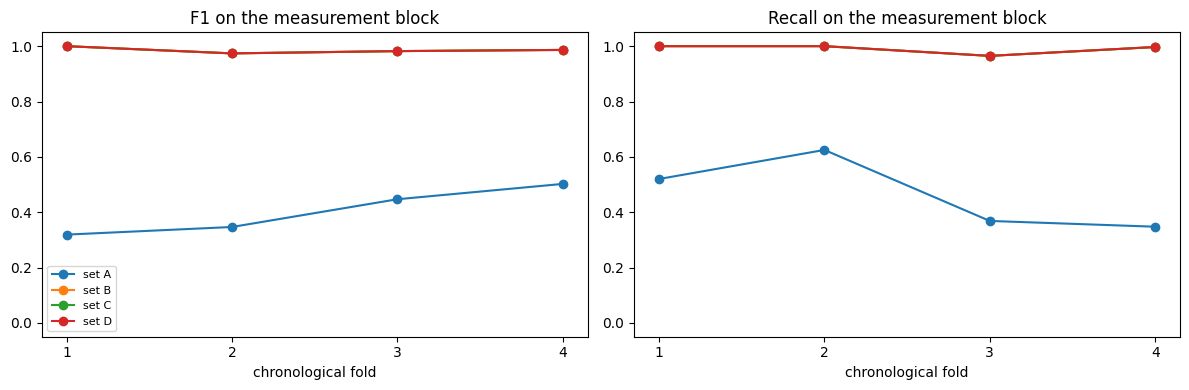

In [17]:
# --- Protocol 2: expanding chronological windows ---
N_BLOCKS = 6
edges = [int(data.step.iloc[int(k * len(data) / N_BLOCKS)]) for k in range(N_BLOCKS)] + [int(data.step.max()) + 1]
print("Block boundaries (hours):", edges)

rolling_rows = []
for k in range(N_BLOCKS - 2):
    tr = data[data.step < edges[k + 1]]
    va = data[(data.step >= edges[k + 1]) & (data.step < edges[k + 2])]
    te = data[(data.step >= edges[k + 2]) & (data.step < edges[k + 3])]
    if min(p.isFraud.nunique() for p in (tr, va, te)) < 2:
        print(f"Fold {k + 1} skipped: one of the parts lacks one of the classes.")
        continue
    for name, columns in FEATURE_SETS.items():
        _, th, _, res = run_experiment(tr, va, te, columns)
        rolling_rows.append({"fold": k + 1, "set": name,
                             "train_rows": len(tr), "frauds_train": int(tr.isFraud.sum()),
                             "frauds_val": int(va.isFraud.sum()), "frauds_measure": int(te.isFraud.sum()),
                             "threshold": th, **{m: res[m] for m in ["AP", "precision", "recall", "F1", "FP", "FN", "TP"]}})
rolling_table = pd.DataFrame(rolling_rows)
rolling_table.to_csv(f"{OUTPUT_DIR}/rolling_windows.csv", index=False)

print("Frauds per fold (train / validation / measurement):")
display(rolling_table[rolling_table.set == "A"][["fold", "frauds_train", "frauds_val", "frauds_measure"]].reset_index(drop=True))

for metric in ["F1", "recall", "precision", "AP"]:
    print(f"{metric} on the measurement block (rows: fold, columns: feature set)")
    display(rolling_table.pivot(index="fold", columns="set", values=metric).round(3))

agg = rolling_table.groupby("set")[["AP", "precision", "recall", "F1"]].agg(["mean", "min"]).round(3)
agg.columns = [f"{m}_{s}" for m, s in agg.columns]
print("Summary over folds (mean and minimum):")
display(agg)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in FEATURE_SETS:
    part = rolling_table[rolling_table.set == name]
    ax[0].plot(part.fold, part.F1, marker="o", label=f"set {name}")
    ax[1].plot(part.fold, part.recall, marker="o", label=f"set {name}")
ax[0].set_title("F1 on the measurement block"); ax[1].set_title("Recall on the measurement block")
for a in ax:
    a.set_xlabel("chronological fold"); a.set_ylim(-0.05, 1.05); a.set_xticks(sorted(rolling_table.fold.unique()))
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/rolling_windows.png", dpi=150)
plt.show()


## 10.4 Summary dashboard

We plot the threshold sensitivity, the ablation study, the final test results and the error types of our tree in one figure. It contains no new computation: it only summarises results that we already obtained above.

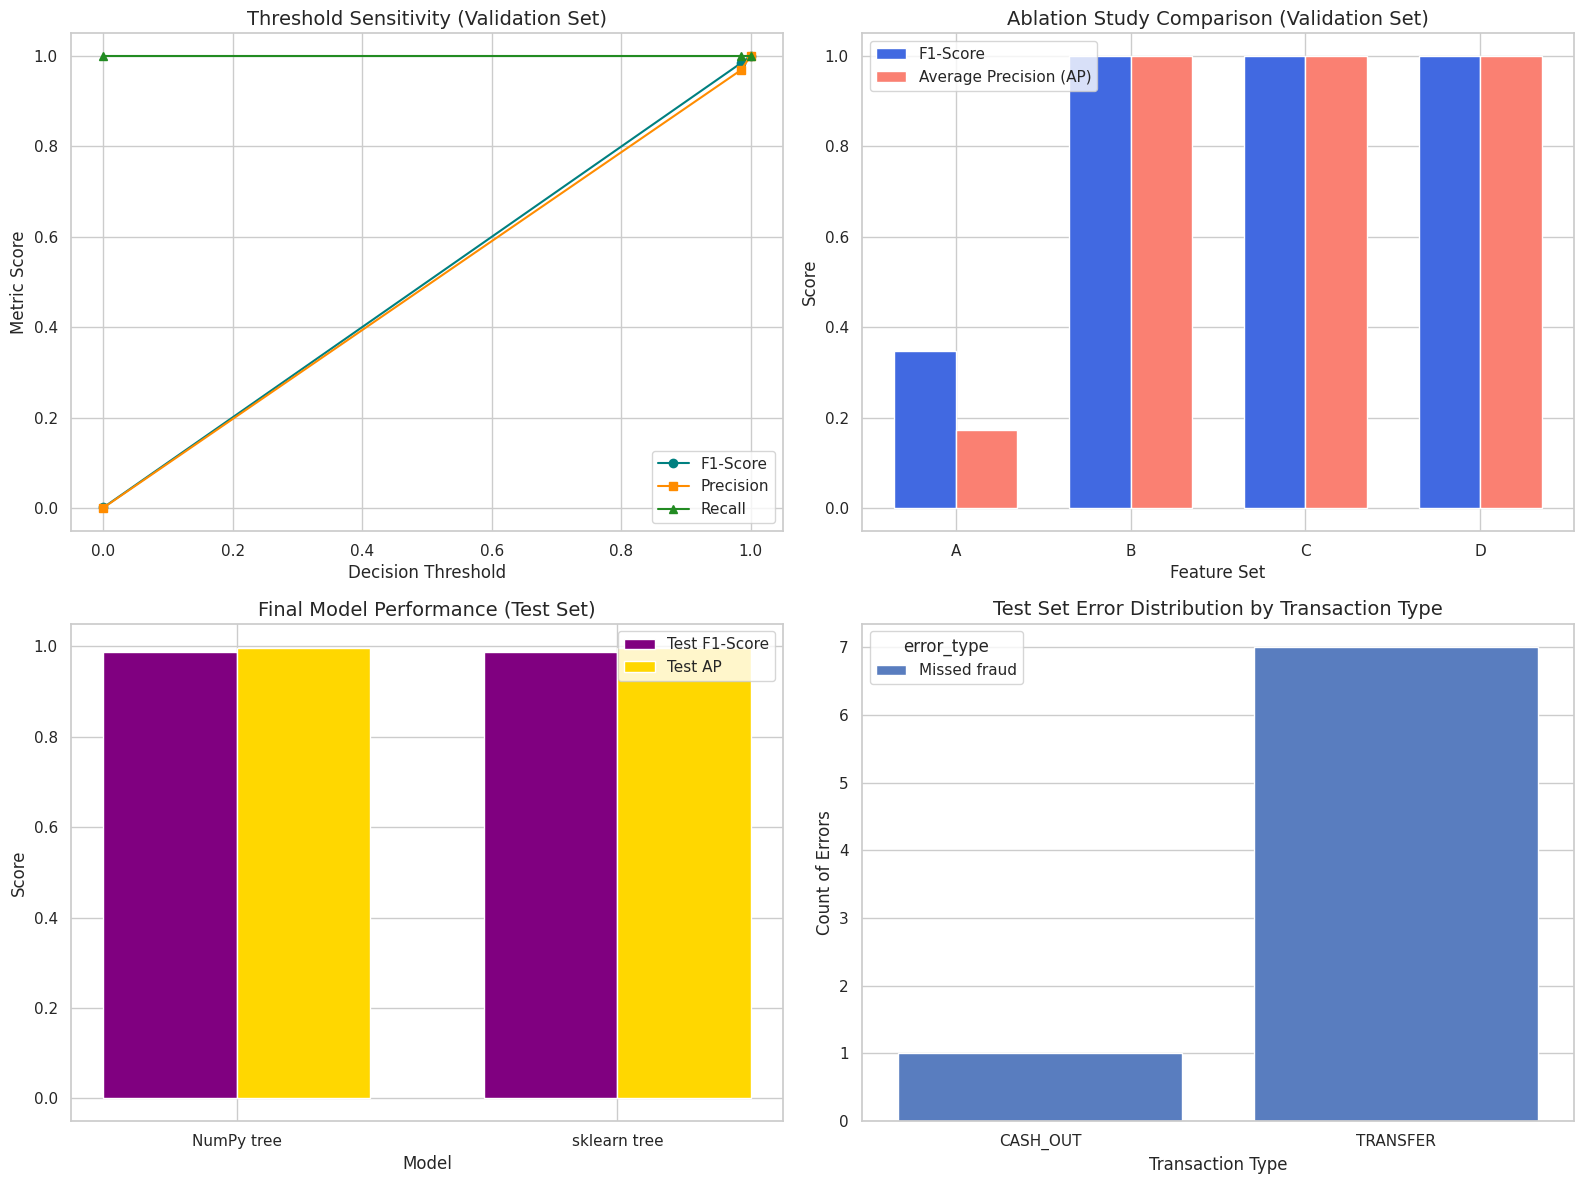

In [18]:
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Threshold Sensitivity (Validation Set)
axes[0, 0].plot(threshold_table["threshold"], threshold_table["F1"], marker='o', label='F1-Score', color='teal')
axes[0, 0].plot(threshold_table["threshold"], threshold_table["precision"], marker='s', label='Precision', color='darkorange')
axes[0, 0].plot(threshold_table["threshold"], threshold_table["recall"], marker='^', label='Recall', color='forestgreen')
axes[0, 0].set_title("Threshold Sensitivity (Validation Set)", fontsize=14)
axes[0, 0].set_xlabel("Decision Threshold")
axes[0, 0].set_ylabel("Metric Score")
axes[0, 0].legend()
axes[0, 0].set_ylim(-0.05, 1.05)

# 2. Ablation Study - Feature Sets vs F1-Score & AP
x_indices = np.arange(len(ablation_table))
width = 0.35
axes[0, 1].bar(x_indices - width/2, ablation_table["F1"], width, label='F1-Score', color='royalblue')
axes[0, 1].bar(x_indices + width/2, ablation_table["AP"], width, label='Average Precision (AP)', color='salmon')
axes[0, 1].set_title("Ablation Study Comparison (Validation Set)", fontsize=14)
axes[0, 1].set_xlabel("Feature Set")
axes[0, 1].set_ylabel("Score")
axes[0, 1].set_xticks(x_indices)
axes[0, 1].set_xticklabels(ablation_table["set"])
axes[0, 1].legend()
axes[0, 1].set_ylim(-0.05, 1.05)

# 3. Model Comparison on Test Set (F1 & AP)
model_names = results["model"].tolist()
x_models = np.arange(len(results))
axes[1, 0].bar(x_models - width/2, results["F1"], width, label='Test F1-Score', color='purple')
axes[1, 0].bar(x_models + width/2, results["AP"], width, label='Test AP', color='gold')
axes[1, 0].set_title("Final Model Performance (Test Set)", fontsize=14)
axes[1, 0].set_xlabel("Model")
axes[1, 0].set_ylabel("Score")
axes[1, 0].set_xticks(x_models)
axes[1, 0].set_xticklabels(model_names)
axes[1, 0].legend()
axes[1, 0].set_ylim(-0.05, 1.05)

# 4. Error distribution comparison
error_counts = errors.groupby(["error_type", "type"]).size().reset_index(name="count")
sns.barplot(data=error_counts, x="type", y="count", hue="error_type", ax=axes[1, 1], palette="muted")
axes[1, 1].set_title("Test Set Error Distribution by Transaction Type", fontsize=14)
axes[1, 1].set_xlabel("Transaction Type")
axes[1, 1].set_ylabel("Count of Errors")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/comprehensive_dashboard.png", dpi=150)
plt.show()

## 11. Discussion, limitations and conclusion

**What we implemented:** We wrote a CART classification tree in NumPy: weighted Gini impurity, vectorised search of the best split, recursive construction and prediction. With the same features, class weights, depth and minimum leaf size, it gave the same result as scikit-learn's `DecisionTreeClassifier`: same threshold, same confusion matrix (339 detected frauds, 8 missed frauds, 0 false alarms) and same AP (0.997) on the test set. The two trees could in principle differ because of ties and numerical tolerances. In our experiment they did not.

**What the results do and do not show:** The good test scores should not be read as "decision trees are very effective against fraud". Our ablation study (Section 10.3) shows that the result depends on one feature. Without the ratio `amount_to_balance` (set A), the validation F1-score falls to 0.346, with 43 false positives and 40 false negatives. As soon as the ratio is available, the F1-score is close to 1, and removing the initial balances (set D) does not change this. The performance therefore comes mainly from our feature engineering, which describes the rule "the account is emptied" that PaySim uses to generate fraud. The tree finds the right split on this feature, but it did not discover the pattern from the raw variables.

**Fragility of the threshold:** On the validation set, the threshold 1.0 gives F1 = 1.0, but a threshold of 0.985 adds 2 false positives and lowers the precision to 0.969 (F1 = 0.984). On the test set, 7 of the 8 missed frauds are TRANSFERs of exactly 10,000,000 that fall into a leaf with score 0.985, just below our threshold. Our threshold choice was therefore decided by a very small number of transactions.

**Limitations:**

| Limitation | Consequence |
|:--|:--|
| Very few frauds (238 in training, 62 in validation, 347 in test) | One transaction can move recall and precision by several points |
| Change of fraud rate over time (0.08 % in training, 0.34 % in test) | A threshold chosen on the past may not fit later periods |
| Random sample of 500,000 rows, one simulated dataset | We cannot generalise to the full dataset or to real transactions |
| Simulator artifact (fraud empties the account) | Real fraud is more varied and adapts to the detection rules |
| Pre-transaction balances assumed to be available | To be checked in a real system |
| Threshold chosen by F1 | An operational system would need an explicit cost or a budget of false alarms |

**Conclusion:** We implemented a decision tree from scratch, verified it and obtained the same results as scikit-learn. The main lesson, however, is about the data: on PaySim, a single well-chosen feature explains almost all the performance, and this feature reflects how the simulator creates fraud. A next step would be to test the method on real or more realistic data and to build features that describe the behaviour of accounts over time.

In [19]:
split_table.to_csv(f"{OUTPUT_DIR}/splits.csv", index=False)
validation_results.to_csv(f"{OUTPUT_DIR}/validation.csv", index=False)
results.to_csv(f"{OUTPUT_DIR}/test.csv", index=False)
errors.to_csv(f"{OUTPUT_DIR}/errors.csv", index=False)
configuration = {"seed": SEED, "n_rows": N_ROWS, "max_depth": MAX_DEPTH,
    "min_samples_leaf": MIN_SAMPLES_LEAF, "use_time": USE_TIME,
    "features": feature_names,
    "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__}
with open(f"{OUTPUT_DIR}/configuration.json", "w") as file:
    json.dump(configuration, file, indent=2)
print("Tables, figures and configuration saved in", OUTPUT_DIR)

Tables, figures and configuration saved in project_results
